# Introduction

L’idée principale est de modéliser le réseau de métro parisien à partir des données fournies (stations, liaisons, flux de passagers), puis d’appliquer des modifications pour simuler des dégradations du réseau (inter-stations supprimées) et observer les impacts sur les flux, les temps de trajet moyens, et déterminer les liaisons critiques.

Description des données utilisées :

- Stations : Une liste des stations de métro avec leurs coordonnées GPS, permettant de positionner chaque station sur le réseau et de calculer les distances entre elles.

- Liaisons : Un fichier décrivant les connexions entre les stations, formant la structure du réseau. Chaque liaison est définie par une station de départ et une station d’arrivée.

- Flux de passagers : Un ensemble de données représentant le nombre de passagers se déplaçant entre les stations. Ces flux sont utilisés pour évaluer la charge sur chaque station et chaque liaison.

# Librairie Importation

In [1]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from haversine import haversine, Unit
import random
from networkx.readwrite import json_graph
import json
import csv
import os


# Configuration

In [2]:

# Parameter to define if the distance for every edge is fixed (dist = 1) or calculated
USE_FIXED_DISTANCE = True  # Set to True to use dist = 1 for all edges, False to calculate real distances

# Parameter to define if passenger flow should be weighted proportionally across nodes and edges
USE_PASSENGER_PONDERATION = False  # Set to True to distribute passengers proportionally across path items (nodes + edges)

# Parameter to define if visualization includes positions (GPS) or uses layout algorithms
USE_POSITIONS = False  # Set to True to use node positions (if available), False to use layout algorithms for visualization

# Graine aleatoire pour que les resultats soient reproductibles
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Dossiers d'entree / sortie
DATA_DIR = 'data'
RESULTS_DIR = 'results'
os.makedirs(RESULTS_DIR, exist_ok=True)


# Chargement des Données

In [3]:
# Load the datasets
passagers = pd.read_csv(f'{DATA_DIR}/passagers.csv', encoding='utf-8')
plan = pd.read_csv(f'{DATA_DIR}/plan_du_metro.csv', encoding='utf-8')
positions = pd.read_csv(f'{DATA_DIR}/position_gps_des_stations_de_metro.csv', encoding='utf-8')

# Quick display to check the data
display(passagers.head())
display(plan.head())
display(positions.head())


,de,vers,nombre
0,La Défense,Esplanade de La Défense,7
1,La Défense,Pont de Neuilly,5
2,La Défense,Les Sablons,6
3,La Défense,Porte Maillot,6
4,La Défense,Argentine,5


,de Ligne,de Station,vers Ligne,vers Station
0,1,Charles de Gaulle - Étoile,2,Charles de Gaulle - Étoile
1,1,Charles de Gaulle - Étoile,6,Charles de Gaulle - Étoile
2,1,Franklin D. Roosevelt,9,Franklin D. Roosevelt
3,1,Champs-Élysées - Clemenceau,13,Champs-Élysées - Clemenceau
4,1,Concorde,8,Concorde


,Station,GPS
0,Abbesses,"48.884594208027806, 2.3379497756920697"
1,Aimé Césaire,"48.90808243782026, 2.377741481106109"
2,Alésia,"48.82818847631351, 2.3271646496078247"
3,Alexandre Dumas,"48.85622809125615, 2.3946756547920462"
4,Alma - Marceau,"48.86476684497177, 2.3009910034955845"


# Nettoyage des Données

In [4]:
def clean_data(positions):
    # Supprimer les doublons basés sur le nom de la station
    positions_cleaned = positions.drop_duplicates(subset='Station')

    # Création d'un dictionnaire station -> (lat, lon)
    station_positions = {}
    for idx, row in positions_cleaned.iterrows():
        station = row['Station']
        latlon = row['GPS'].split(',')
        lat = float(latlon[0].strip())
        lon = float(latlon[1].strip())
        station_positions[station] = (lat, lon)
    
    return station_positions, positions_cleaned

station_positions, positions_cleaned = clean_data(positions)
print("Nombre de stations uniques après nettoyage :", len(positions_cleaned))

Nombre de stations uniques après nettoyage : 307


# Construction du graphe

Les stations presentes dans le plan mais absentes du fichier GPS sont ajoutees quand meme au graphe, sans position.

Number of stations (nodes): 307
Number of connections (edges): 377


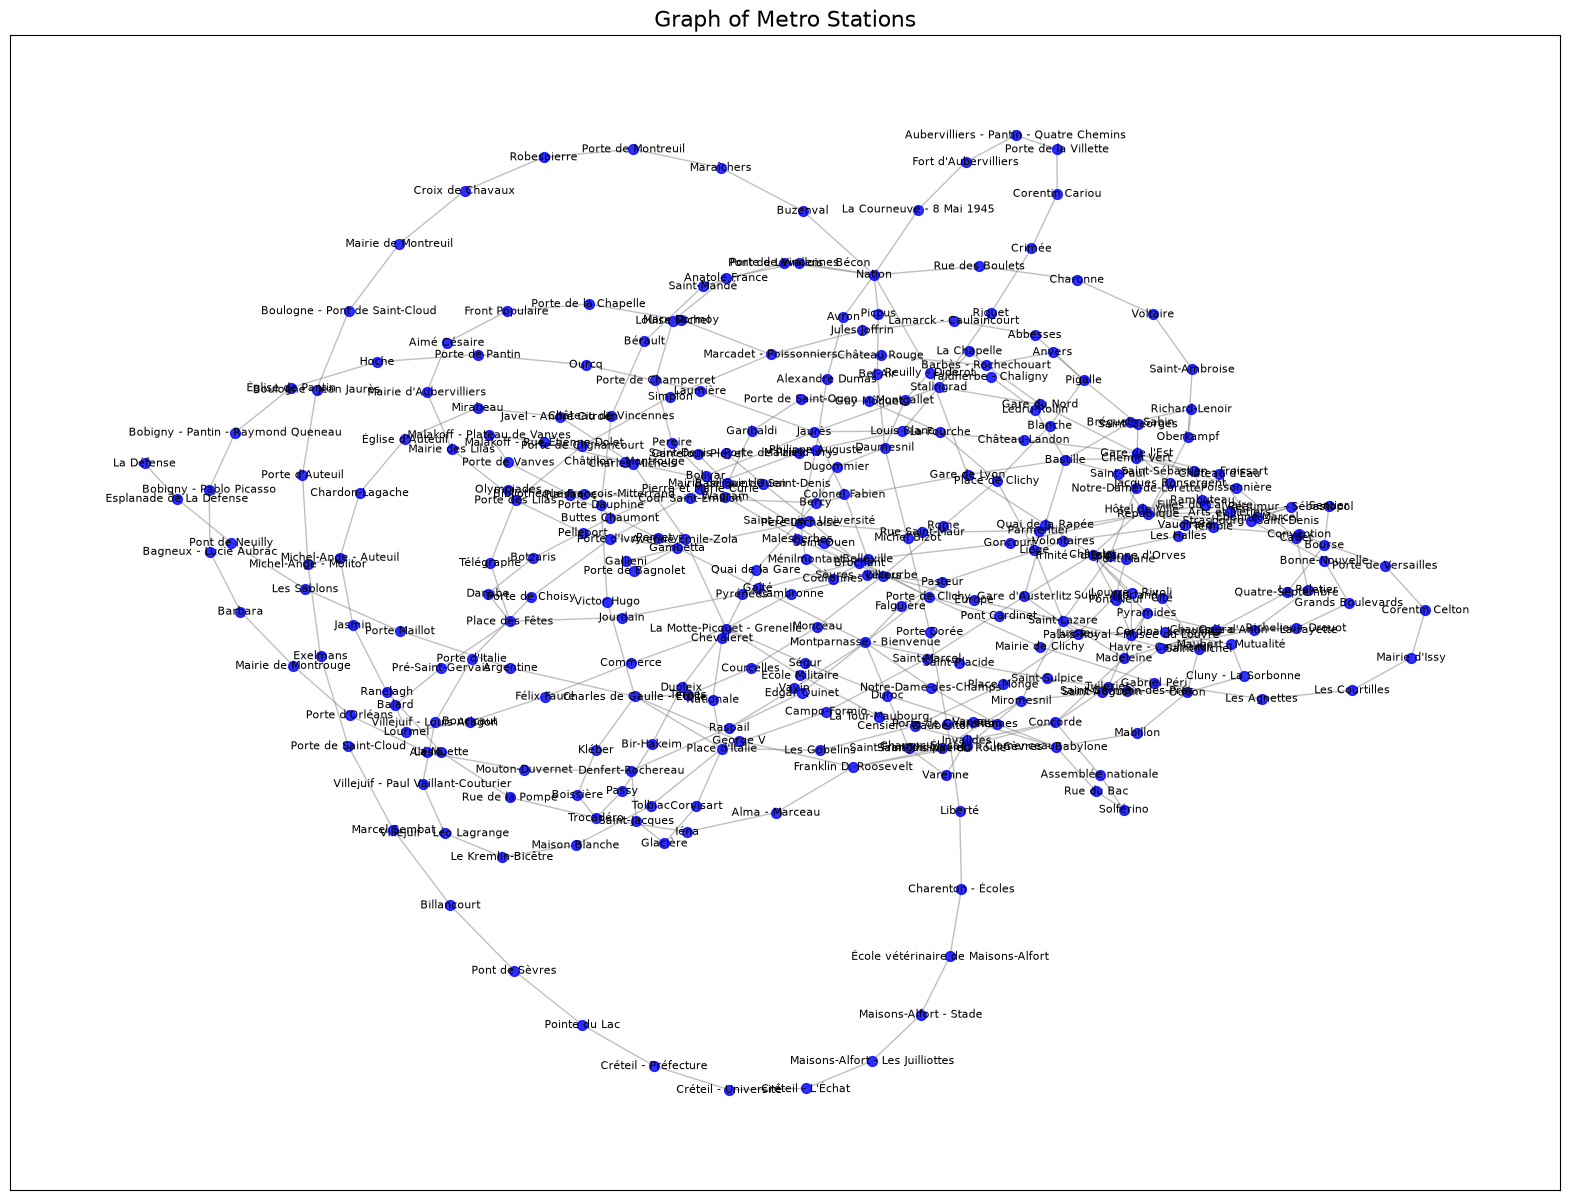

In [5]:

def build_metro_graph(plan, station_positions, use_positions, use_fixed_distance):
  
    G = nx.Graph()
    skipped_stations = []  # To keep track of skipped stations

    # Add all stations with positions if use_positions is True
    if use_positions:
        for station in station_positions:
            lat, lon = station_positions[station]
            G.add_node(station, pos=(lon, lat))

        for station in set(plan['vers Station']).union(plan['de Station']):
            if station not in G:  # Ensure each station is added only once

                # Create missing positions by calculating the midpoint between connected stations
                connected_stations = plan[
                    (plan['de Station'] == station) | (plan['vers Station'] == station)
                ]

                # Include already calculated positions if possible
                connected_positions = [
                    station_positions[s]
                    for s in connected_stations['de Station'].tolist() + connected_stations['vers Station'].tolist()
                    if s in station_positions
                ]

                if len(connected_positions) >= 2:  # Need at least two stations with positions
                    # Calculate the midpoint
                    mid_lat = sum(pos[0] for pos in connected_positions) / len(connected_positions)
                    mid_lon = sum(pos[1] for pos in connected_positions) / len(connected_positions)
                    G.add_node(station, pos=(mid_lon, mid_lat))  # Add with calculated position
                else:
                    # Track skipped stations
                    skipped_stations.append(station)

    else:
        # Add all unique stations without positions
        for station in station_positions:
            G.add_node(station)  # Add node without position
        for station in set(plan['vers Station']).union(plan['de Station']):
            if station not in G:  # Ensure each station is added only once
                G.add_node(station)  # Add node without position

    # Retry for skipped stations at the end
    if use_positions and skipped_stations:
        for station in skipped_stations:
            connected_stations = plan[
                (plan['de Station'] == station) | (plan['vers Station'] == station)
            ]

            connected_positions = [
                nx.get_node_attributes(G, 'pos').get(s)
                for s in connected_stations['de Station'].tolist() + connected_stations['vers Station'].tolist()
                if nx.get_node_attributes(G, 'pos').get(s) is not None
            ]

            if len(connected_positions) >= 2:  # Check again for sufficient neighbors
                # Recalculate the midpoint
                mid_lat = sum(pos[1] for pos in connected_positions) / len(connected_positions)
                mid_lon = sum(pos[0] for pos in connected_positions) / len(connected_positions)
                G.add_node(station, pos=(mid_lon, mid_lat))  # Add with recalculated position
            else:
                print(f"Station {station} still skipped: no sufficient neighbors even after retry.")

    # Add edges
    for idx, row in plan.iterrows():
        s1 = row['de Station']
        s2 = row['vers Station']
        if s1 != s2:
            if use_fixed_distance:
                dist = 1  # Use fixed distance
            else:
                # Calculate haversine distance if positions are available
                if s1 in station_positions and s2 in station_positions:
                    lat1, lon1 = station_positions[s1]
                    lat2, lon2 = station_positions[s2]
                    dist = haversine((lat1, lon1), (lat2, lon2), unit=Unit.KILOMETERS)
                else:
                    dist = 1  # Default to 1 if positions are missing

            G.add_edge(s1, s2, weight=dist)

    print("Number of stations (nodes):", G.number_of_nodes())
    print("Number of connections (edges):", G.number_of_edges())

    # Visualization of the graph
    plt.figure(figsize=(20, 15))  # Adjust figure size for readability

    if use_positions:
        # Use GPS positions if enabled
        pos = nx.get_node_attributes(G, 'pos')
        nodes_with_positions = [node for node in G.nodes() if node in pos]
        G = G.subgraph(nodes_with_positions)  # Restrict graph to nodes with positions
    else:
        # Use a layout algorithm if positions are disabled
        pos = nx.spring_layout(G)

    # Draw nodes
    nx.draw_networkx_nodes(G, pos, node_size=50, node_color='blue', alpha=0.8)

    # Draw edges
    nx.draw_networkx_edges(G, pos, edge_color='gray', alpha=0.5)

    # Draw labels
    nx.draw_networkx_labels(G, pos, font_size=8, font_color='black', font_family='sans-serif')

    plt.title("Graph of Metro Stations", fontsize=16)
    plt.show()

    return G

G = build_metro_graph(plan, station_positions, USE_POSITIONS, USE_FIXED_DISTANCE)
  

# Calcul des flux passagers

In [6]:
def calculate_passenger_flow(G, passagers, use_passenger_ponderation):
    """
    Calculate passenger flow through the network, including edge and station flows, 
    and travel distances per passenger.

    Args:
        G (nx.Graph): The graph representing the network.
        passagers (pd.DataFrame): Passenger data with 'de', 'vers', and 'nombre'.
        use_passenger_ponderation (bool): Whether to calculate flow with ponderation.

    Returns:
        tuple: 
            - flux_par_arete (dict): Flow by edges.
            - flux_par_station (dict): Flow by stations.
            - avg_travel_distance (float): Average travel distance per passenger.
            - travel_par_passager (list): List of travel distances per passenger.
    """
    flux_par_arete = {}  # Flow by edges
    flux_par_station = {}  # Flow by stations
    total_passengers = 0
    travel_par_passager = []  # Travel distance (distance * nb passengers) per origin-destination pair

    # On garde uniquement les couples dont les 2 stations existent dans le graphe
    valid = passagers[passagers['de'].isin(G.nodes) & passagers['vers'].isin(G.nodes)]

    # Un seul Dijkstra par station de depart (au lieu d'un par couple)
    for start, group in valid.groupby('de'):
        dists, paths = nx.single_source_dijkstra(G, source=start, weight='weight')

        for end, nb in zip(group['vers'], group['nombre']):
            if end not in paths:
                print(f"ERROR: No existing path between station {start} and station {end}")
                continue

            path = paths[end]
            dist_path = dists[end]

            # Calculate passenger contribution per item (nodes + edges) if ponderation is enabled
            if use_passenger_ponderation:
                total_items = len(path) + (len(path) - 1)  # nodes + edges
                contribution_per_item = nb / total_items
            else:
                contribution_per_item = nb

            for i in range(len(path) - 1):
                e1, e2 = path[i], path[i + 1]

                # Update the flow on the edge (cle triee : le graphe est non oriente)
                key = tuple(sorted((e1, e2)))
                flux_par_arete[key] = flux_par_arete.get(key, 0) + contribution_per_item

                # Update the flow on the stations
                flux_par_station[e1] = flux_par_station.get(e1, 0) + contribution_per_item
                flux_par_station[e2] = flux_par_station.get(e2, 0) + contribution_per_item

            travel_par_passager.append(dist_path * nb)
            total_passengers += nb

    return flux_par_arete, flux_par_station, travel_par_passager, total_passengers # add nb total of passager

# Call the updated function
flux_par_arete, flux_par_station, travel_par_passager, total_passengers = calculate_passenger_flow(
    G, passagers, USE_PASSENGER_PONDERATION
)

# Calculate the average travel distance from individual passenger distances
if total_passengers:
    avg_travel_distance = sum(travel_par_passager) / total_passengers
else:
    avg_travel_distance = float('nan')

print("Average travel distance (calculated directly):", avg_travel_distance, "km")



Average travel distance (calculated directly): 10.422748099418946 km


# Analyse des points les plus chargées

In [7]:
def display_top_flows(flux_par_arete, flux_par_station, top_n=10):
    # Sort edges by flow
    edges_sorted = sorted(flux_par_arete.items(), key=lambda x: x[1], reverse=True)
    print(f"Top {top_n} most loaded inter-station connections:")
    for i, ((u, v), flux) in enumerate(edges_sorted[:top_n]):
        print(f"{i+1}. {u} -> {v}: {flux:.2f} passengers")

    # Sort nodes by flow
    nodes_sorted = sorted(flux_par_station.items(), key=lambda x: x[1], reverse=True)
    print(f"\nTop {top_n} most loaded stations:")
    for i, (station, flux) in enumerate(nodes_sorted[:top_n]):
        print(f"{i+1}. {station}: {flux:.2f} passengers")

# Call the function to display top flows
display_top_flows(flux_par_arete, flux_par_station, top_n=10)


Top 10 most loaded inter-station connections:
1. Châtelet -> Gare de Lyon: 73816.00 passengers
2. Gare de Lyon -> Reuilly - Diderot: 58869.00 passengers
3. Châtelet -> Pyramides: 56599.00 passengers
4. Nation -> Reuilly - Diderot: 52689.00 passengers
5. Concorde -> Madeleine: 49683.00 passengers
6. Madeleine -> Saint-Lazare: 48163.00 passengers
7. Madeleine -> Pyramides: 48034.00 passengers
8. Pont Cardinet -> Saint-Lazare: 44618.00 passengers
9. Pont Cardinet -> Porte de Clichy: 42152.00 passengers
10. Charles de Gaulle - Étoile -> Place d'Italie: 38373.00 passengers

Top 10 most loaded stations:
1. Châtelet: 243113.00 passengers
2. Gare de Lyon: 174499.00 passengers
3. Saint-Lazare: 166949.00 passengers
4. Nation: 166366.00 passengers
5. Madeleine: 163292.00 passengers
6. Reuilly - Diderot: 131093.00 passengers
7. Charles de Gaulle - Étoile: 124537.00 passengers
8. Place d'Italie: 124290.00 passengers
9. Pyramides: 117919.00 passengers
10. Concorde: 110519.00 passengers


# Sauvegarde des points les plus chargées

In [8]:
def save_overload_matrices(flux_par_arete, flux_par_station, edge_csv=f'{RESULTS_DIR}/Overload_edges.csv', node_csv=f'{RESULTS_DIR}/Overload_nodes.csv'):
    # Create a DataFrame for edge flows
    df_flux = pd.DataFrame([{'station1': u, 'station2': v, 'flux': flux} for ((u, v), flux) in flux_par_arete.items()])
    df_flux_overload = df_flux.sort_values('flux', ascending=False)  # Sort by flux in descending order

    # Create a DataFrame for node flows
    df_station_flux = pd.DataFrame([{'station': station, 'flux': flux} for station, flux in flux_par_station.items()])
    df_station_overload = df_station_flux.sort_values('flux', ascending=False)  # Sort by flux in descending order

    # Save the sorted DataFrames to CSV
    df_flux_overload.to_csv(edge_csv, index=False)
    print(f"Matrix of overload edges saved to {edge_csv}")
    df_station_overload.to_csv(node_csv, index=False)
    print(f"Matrix of overload nodes saved to {node_csv}")

    return df_flux_overload, df_station_overload

# Call the function to save overload matrices
df_flux_overload, df_station_overload = save_overload_matrices(flux_par_arete, flux_par_station)


Matrix of overload edges saved to results/Overload_edges.csv
Matrix of overload nodes saved to results/Overload_nodes.csv


# Visualisation du réseau

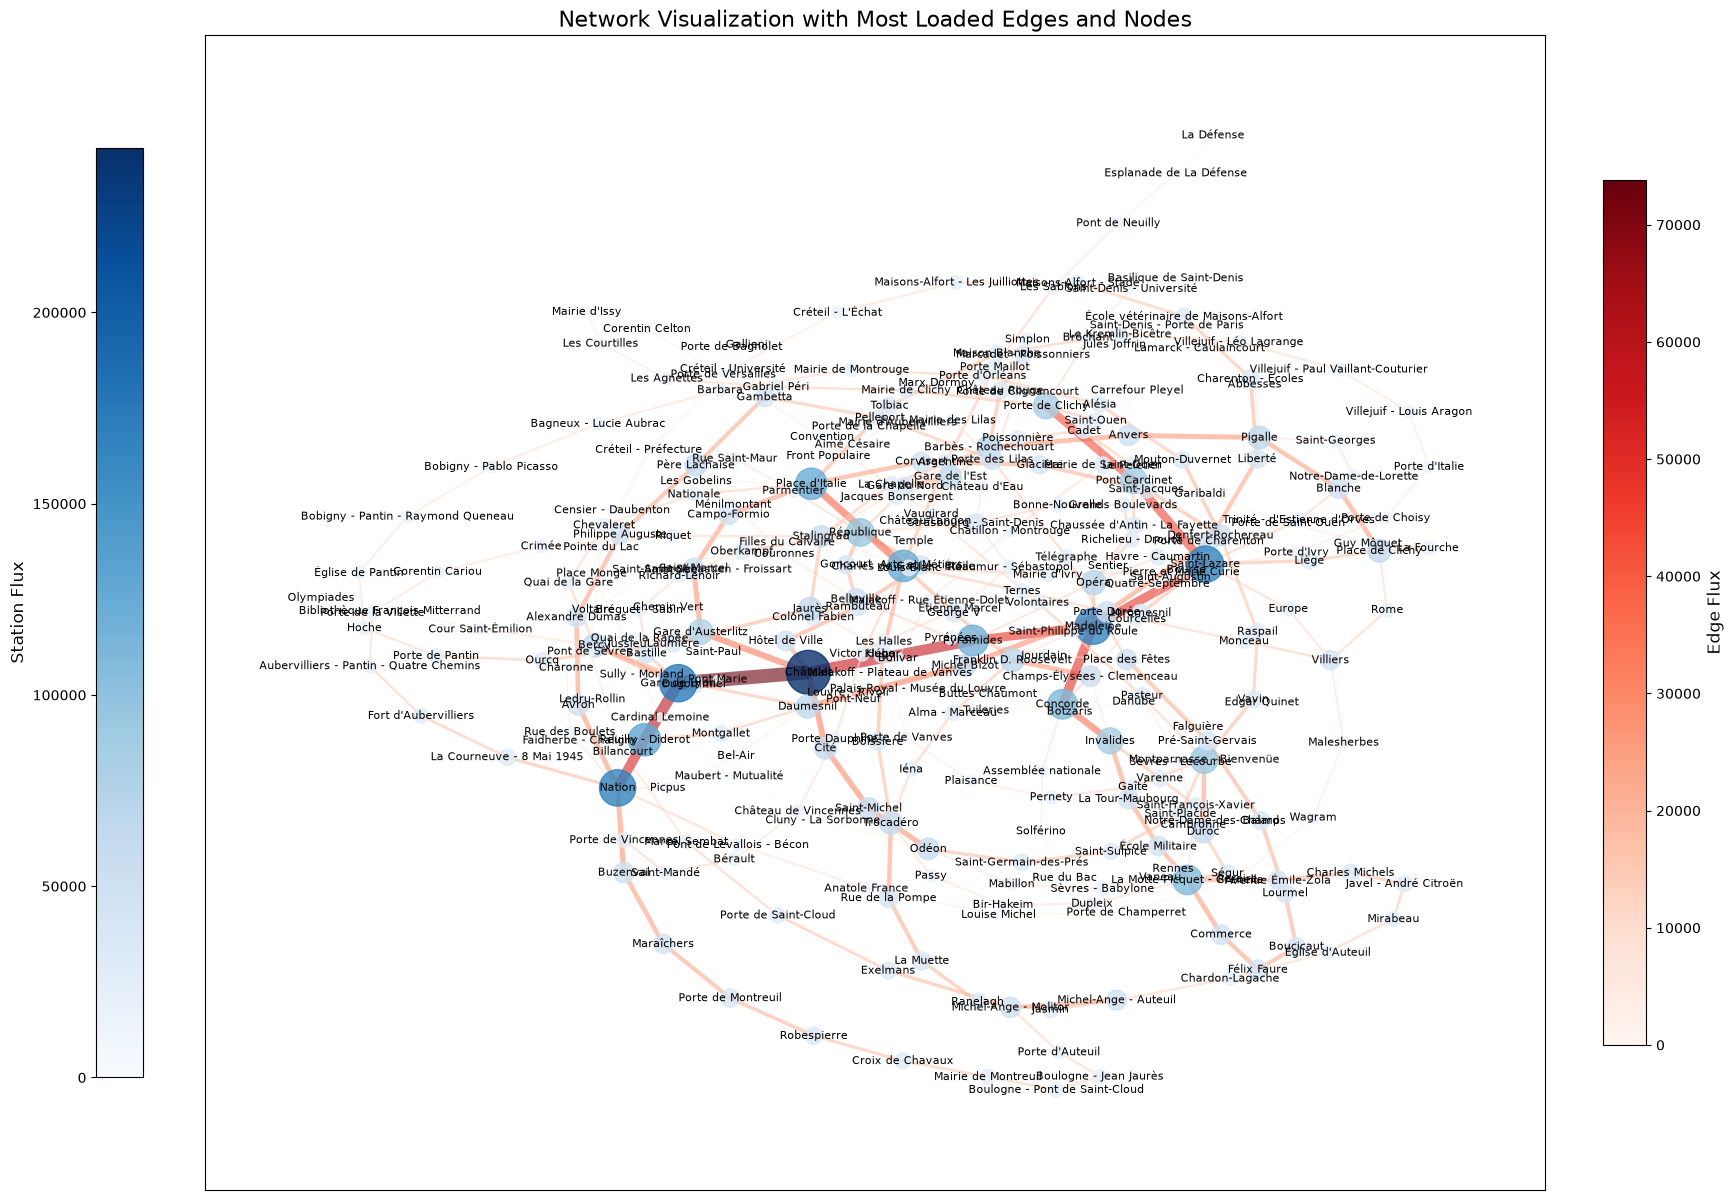

In [9]:
def visualize_network(G, flux_par_arete, flux_par_station, use_positions=True, figsize=(20, 15)):
   
    # Create a single figure and axes
    fig, ax = plt.subplots(figsize=figsize)

    # Use positions if available or spring layout otherwise
    if use_positions:
        pos = nx.get_node_attributes(G, 'pos')
    else:
        pos = nx.spring_layout(G)  # Automatic layout if positions are not used

    # Normalize node and edge weights for visualization purposes
    max_station_flux = max(flux_par_station.values()) if flux_par_station else 1
    max_edge_flux = max(flux_par_arete.values()) if flux_par_arete else 1

    # Node sizes and colors based on station flux
    node_sizes = [flux_par_station.get(node, 0) / max_station_flux * 1000 for node in G.nodes()]
    node_colors = [flux_par_station.get(node, 0) / max_station_flux for node in G.nodes()]

    # Edge widths and colors based on edge flux
    edge_widths = [flux_par_arete.get(tuple(sorted((u, v))), 0) / max_edge_flux * 10 for u, v in G.edges()]
    edge_colors = [flux_par_arete.get(tuple(sorted((u, v))), 0) / max_edge_flux for u, v in G.edges()]

    # Draw nodes with sizes and colors reflecting their flux
    nx.draw_networkx_nodes(
        G, pos, node_size=node_sizes, node_color=node_colors, cmap=plt.cm.Blues, alpha=0.8, ax=ax
    )

    # Draw edges with widths and colors reflecting their flux
    nx.draw_networkx_edges(
        G, pos, width=edge_widths, edge_color=edge_colors, edge_cmap=plt.cm.Reds, alpha=0.6, ax=ax
    )

    # Draw labels for nodes
    nx.draw_networkx_labels(G, pos, font_size=8, font_color='black', font_family='sans-serif', ax=ax)

    # Add node colorbar
    sm_nodes = plt.cm.ScalarMappable(cmap=plt.cm.Blues, norm=plt.Normalize(vmin=0, vmax=max_station_flux))
    cbar_nodes = fig.colorbar(sm_nodes, ax=ax, fraction=0.03, pad=0.04, location="left")
    cbar_nodes.set_label("Station Flux", fontsize=12)

    # Add edge colorbar
    sm_edges = plt.cm.ScalarMappable(cmap=plt.cm.Reds, norm=plt.Normalize(vmin=0, vmax=max_edge_flux))
    cbar_edges = fig.colorbar(sm_edges, ax=ax, fraction=0.03, pad=0.04, location="right")
    cbar_edges.set_label("Edge Flux", fontsize=12)

    plt.title("Network Visualization with Most Loaded Edges and Nodes", fontsize=16)
    plt.show()

# Call the function to visualize the network
visualize_network(
    G, flux_par_arete, flux_par_station, use_positions=USE_POSITIONS, figsize=(20, 15)
)


# Creation dataset d'entrainement

# List of contournable_connections

In [10]:
def find_contournable_connections(G):
    """Retourne les aretes dont la suppression ne deconnecte pas le graphe.

    Une arete est contournable si ce n'est pas un pont (nx.bridges).
    Equivalent a l'ancienne version (copie du graphe + has_path pour chaque arete)
    mais beaucoup plus rapide.
    """
    bridges = {frozenset(e) for e in nx.bridges(G)}
    return [(u, v) for u, v in G.edges() if frozenset((u, v)) not in bridges]

# Call the function to find contournable connections
contournable_connections = find_contournable_connections(G)

print("Number of contournable connections:", len(contournable_connections))


Number of contournable connections: 368


# Example of creation of a degraded graph 

Removing the 5 following connections: [('Pierre et Marie Curie', "Porte d'Ivry"), ('Blanche', 'Pigalle'), ('Anvers', 'Pigalle'), ('Concorde', 'Madeleine'), ("Chaussée d'Antin - La Fayette", 'Le Peletier')]
Degraded plan saved to results/plan_du_metro_degrade.csv
Number of stations (nodes): 307
Number of connections (edges): 372


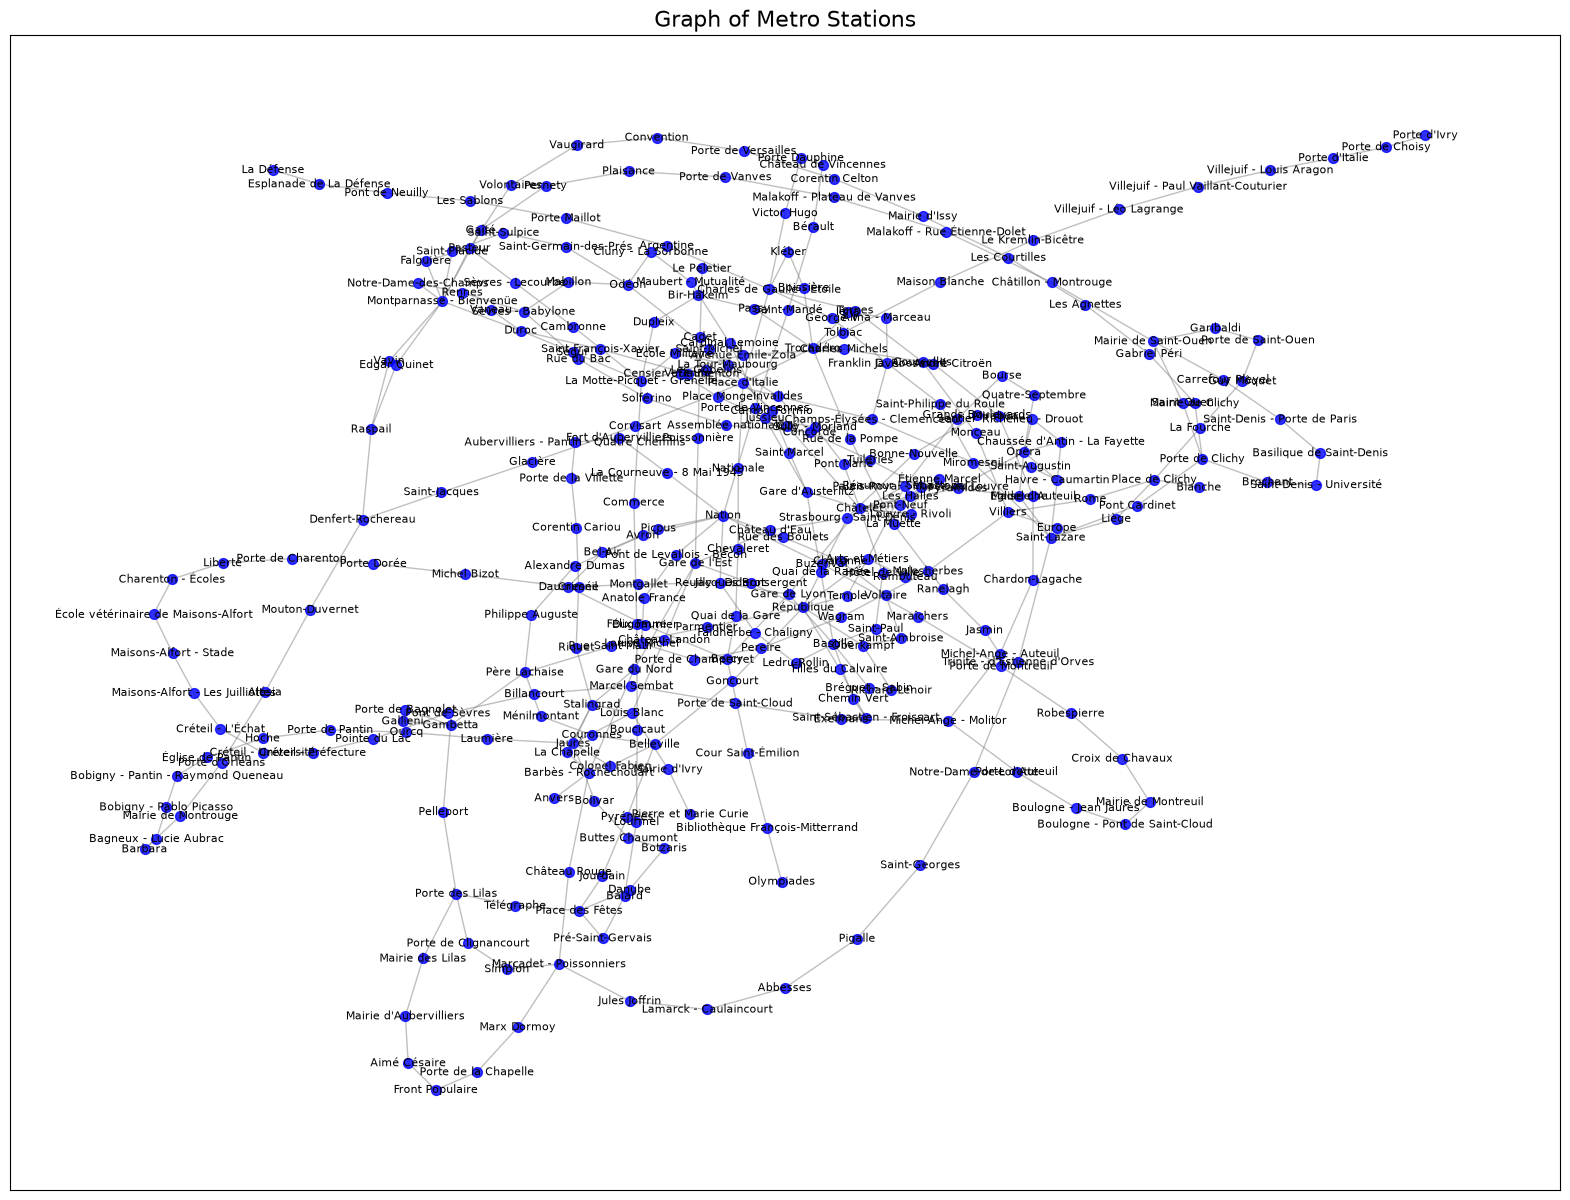

In [11]:
def degrade_plan(plan, contournable_connections, nb_deleted_connections, output_file=f'{RESULTS_DIR}/plan_du_metro_degrade.csv'):

    # random selection of connections
    if len(contournable_connections) < nb_deleted_connections:
        print(f"Warning: Only {len(contournable_connections)} contournable connections available.")
        nb_deleted_connections = len(contournable_connections)
    
    # Randomly select the connections to remove
    connections_to_remove = random.sample(contournable_connections, nb_deleted_connections)
    print(f"Removing the {nb_deleted_connections} following connections: {connections_to_remove}")

    # Remove these connections from the plan DataFrame
    for u, v in connections_to_remove:
        plan = plan[
            ~(
                ((plan['de Station'] == u) & (plan['vers Station'] == v)) |
                ((plan['de Station'] == v) & (plan['vers Station'] == u))
            )
        ]

    # Save the updated plan to a file
    plan.to_csv(output_file, index=False)
    print(f"Degraded plan saved to {output_file}")

    return plan

contournable_connections = find_contournable_connections(G)

# Call the function to degrade the plan
degraded_plan = degrade_plan(plan, contournable_connections, 5)

# Build the graph 
G_degraded = build_metro_graph(degraded_plan, station_positions, USE_POSITIONS, USE_FIXED_DISTANCE)

# Generate node id CSV for GNN

In [12]:
def generate_node_ids_csv(graph, output_csv="node_ids.csv"):
    with open(output_csv, "w", newline="", encoding="utf-8") as csvfile:
        csvwriter = csv.writer(csvfile)
        csvwriter.writerow(["node", "unique_id"])  # Header row

        print(f"Generating unique IDs for node...")
        for j, node in enumerate(graph.nodes):
            graph.nodes[node]["number"] = j  # Assign unique integer ID
            csvwriter.writerow([node, j])  # Write graph ID, node, and unique ID to CSV

    print(f"Node IDs for graph saved to {output_csv}")


# Generate a CSV file with unique IDs for each node
generate_node_ids_csv(G, f"{RESULTS_DIR}/node_ids.csv")

Generating unique IDs for node...
Node IDs for graph saved to results/node_ids.csv


# Generate Trainning Dataset for GNN 


In [13]:

def generate_random_degraded_graphs(G, nb_graphs, nb_optimal_path):

    degraded_graphs = []

    for i in range(nb_graphs):
        print(f"Generating degraded graph {i + 1}/{nb_graphs}...")

        # Create a copy of the original graph
        G_degraded = G.copy()
        
        contournable_connections = find_contournable_connections(G_degraded)
        if not contournable_connections:
            print("No contournable connections available for degradation.")
            break
        
        lambda_poisson = 8
        # Determine a random number of edges to delete using Poisson distribution
        max_deletable_edges = max(1, len(contournable_connections) // 3)
        n_deleted_edges = min(np.random.poisson(lambda_poisson), max_deletable_edges)
        n_deleted_edges = max(1, n_deleted_edges)  # Ensure at least 1 edge is deleted
        
        print(f"Deleting {n_deleted_edges} edges for graph {i + 1}...")
        
        for _ in range(n_deleted_edges):
            # Recalculate contournable connections at each step
            contournable_connections = find_contournable_connections(G_degraded)

            if not contournable_connections:
                print(f"No more contournable connections available.")
                break

            # Randomly select one edge to delete
            edge_to_remove = random.choice(contournable_connections)

            # Remove the selected edge
            G_degraded.remove_edge(*edge_to_remove) #


        # Compute optimal paths using Dijkstra's algorithm
        optimal_paths = {}
        nodes = list(G_degraded.nodes)
        
        if len(nodes) > 1:
            # Select unique random pairs of nodes
            node_pairs = random.sample([(u, v) for u in nodes for v in nodes if u != v], min(nb_optimal_path, len(nodes) * (len(nodes) - 1)))

            for u, v in node_pairs:
                try:
                    path = nx.shortest_path(G_degraded, source=u, target=v, weight='weight', method='dijkstra')
                    optimal_paths[f"{u},{v}"] = path  # Convert tuple to string key
                except nx.NetworkXNoPath:
                    pass

        # Store optimal paths in the graph attribute
        G_degraded.graph['optimal_paths'] = optimal_paths

        # Add the degraded graph to the list
        degraded_graphs.append(G_degraded)

    return degraded_graphs

def save_generated_graphs_to_json(graphs, output_file):
    
    # Prepare a list to store all graph data
    generated_graphs_data = []

    for i, graph in enumerate(graphs):
        print(f"Converting graph {i + 1} to JSON format...")
        graph_json = json_graph.node_link_data(graph)
        graph_json['graph_id'] = i + 1  # Add an ID to each graph
        generated_graphs_data.append(graph_json)

    # Save all graphs into a single JSON file
    with open(output_file, "w", encoding="utf-8") as f:
        json.dump(generated_graphs_data, f, indent=4)

    print(f"All graphs saved to {output_file}")

# Generate degraded graphs
degraded_graphs = generate_random_degraded_graphs(G, 5, 100)

# Save all graphs into a single JSON file
save_generated_graphs_to_json(degraded_graphs, f"{RESULTS_DIR}/generated_graphs.json")


Generating degraded graph 1/5...
Deleting 8 edges for graph 1...
Generating degraded graph 2/5...
Deleting 15 edges for graph 2...
Generating degraded graph 3/5...


Deleting 9 edges for graph 3...


Generating degraded graph 4/5...
Deleting 9 edges for graph 4...
Generating degraded graph 5/5...
Deleting 9 edges for graph 5...
Converting graph 1 to JSON format...
Converting graph 2 to JSON format...
Converting graph 3 to JSON format...
Converting graph 4 to JSON format...
Converting graph 5 to JSON format...
All graphs saved to results/generated_graphs.json


# Generate possible graph for 1 contournable_connections deleted 


In [14]:
def generate_simple_degraded_graphs(G):
    """
    Generate degraded graphs by removing one contournable connection at a time.

    Args:
        G (nx.Graph): The original graph.

    Returns:
        list: A list of degraded graphs with one edge removed and optimal paths stored.
    """
    
    degraded_graphs = []

    # Find all contournable connections
    contournable_connections = find_contournable_connections(G)

    if not contournable_connections:
        print("No contournable connections available for degradation.")
        return degraded_graphs

    print(f"Generating {len(contournable_connections)} degraded graphs (one edge removed per graph)...")

    # Generate one graph for each possible edge removal
    for i, edge_to_remove in enumerate(contournable_connections):

        # Create a copy of the original graph
        G_degraded = G.copy()

        # Remove the selected edge
        G_degraded.remove_edge(*edge_to_remove)
        
        # Append the degraded graph to the list
        degraded_graphs.append(G_degraded)

    return degraded_graphs

# Generate all degraded graphs with one edge removed
degraded_graphs = generate_simple_degraded_graphs(G)

# Print the number of graphs generated
print(f"Generated {len(degraded_graphs)} degraded graphs.")


Generating 368 degraded graphs (one edge removed per graph)...


Generated 368 degraded graphs.


ITERATIVE function , to handle the case want we want all graph the have 2 or more inter contournable removed we can all the 1 then for each 1 we do one more (so the 2) then same again and again

# Analyse graph for 1 contournable_connections deleted 

In [15]:

def analyze_edges(base_flux_par_arete, degraded_flux_par_arete):
    """
    Analyze edge flow differences between the baseline graph and a degraded graph.

    Args:
        base_flux_par_arete (dict): Edge flows for the baseline graph.
        degraded_flux_par_arete (dict): Edge flows for the degraded graph.

    Returns:
        tuple: 
            - avg_flow_diff_edges (float): Average percentage difference in edge flows.
            - max_diff_edge (float): Maximum percentage difference in edge flows.
            - std_diff_edge (float): Standard deviation of edge flow differences.
    """
    edge_diffs = []  # List to store percentage differences for each edge

    # Compare flows for edges present in both graphs
    for edge in base_flux_par_arete:
        if edge in degraded_flux_par_arete:
            base_flow = base_flux_par_arete[edge]
            degraded_flow = degraded_flux_par_arete[edge]
            if base_flow > 0:  # Avoid division by zero
                diff = abs(degraded_flow - base_flow) / base_flow * 100  # Percentage difference
                edge_diffs.append(diff)

    # Calculate average, maximum, and standard deviation of edge flow differences
    avg_flow_diff_edges = sum(edge_diffs) / len(edge_diffs) if edge_diffs else float('nan')
    max_diff_edge = max(edge_diffs) if edge_diffs else float('nan')
    std_diff_edge = np.std(edge_diffs) if edge_diffs else float('nan')

    return avg_flow_diff_edges, max_diff_edge, std_diff_edge

def analyze_nodes(base_flux_par_station, degraded_flux_par_station):
    """
    Analyze station flow differences between the baseline graph and a degraded graph.

    Args:
        base_flux_par_station (dict): Station flows for the baseline graph.
        degraded_flux_par_station (dict): Station flows for the degraded graph.

    Returns:
        tuple: 
            - avg_flow_diff_nodes (float): Average percentage difference in station flows.
            - max_diff_nodes (float): Maximum percentage difference in station flows.
            - std_diff_nodes (float): Standard deviation of station flow differences.
    """
    station_diffs = []  # List to store percentage differences for each station

    # Compare flows for stations present in both graphs
    for station in base_flux_par_station:
        if station in degraded_flux_par_station:
            base_flow = base_flux_par_station[station]
            degraded_flow = degraded_flux_par_station[station]
            if base_flow > 0:  # Avoid division by zero
                diff = abs(degraded_flow - base_flow) / base_flow * 100  # Percentage difference
                station_diffs.append(diff)

    # Calculate average, maximum, and standard deviation of station flow differences
    avg_flow_diff_nodes = sum(station_diffs) / len(station_diffs) if station_diffs else float('nan')
    max_diff_nodes = max(station_diffs) if station_diffs else float('nan')
    std_diff_nodes = np.std(station_diffs) if station_diffs else float('nan')

    return avg_flow_diff_nodes, max_diff_nodes, std_diff_nodes

def analyze_passengers(base_travel_par_passager, degraded_travel_par_passager, total_passengers):
    """
    Analyze passenger travel distance differences between the baseline graph and a degraded graph.

    Args:
        base_travel_par_passager (list): Travel distances per passenger in the baseline graph.
        degraded_travel_par_passager (list): Travel distances per passenger in the degraded graph.
        total_passengers (int): Total number of passengers.

    Returns:
        tuple:
            - avg_diff_distance (float): Percentage difference in average travel distance.
            - max_diff_passengers (float): Absolute maximum difference in travel distance.
            - std_diff_passengers (float): Standard deviation of travel distance differences.
    """
    # Calculate average travel distances
    if total_passengers > 0:
        base_avg_distance = sum(base_travel_par_passager) / total_passengers
        degraded_avg_distance = sum(degraded_travel_par_passager) / total_passengers
    else:
        base_avg_distance = degraded_avg_distance = float('nan')

    # Calculate percentage difference in average travel distance
    avg_diff_distance = (abs(degraded_avg_distance - base_avg_distance) / base_avg_distance * 100
                         if base_avg_distance > 0 else float('nan'))

    # Calculate per-passenger travel differences
    if len(base_travel_par_passager) == len(degraded_travel_par_passager):
        travel_differences = [
            abs(degraded - base)
            for base, degraded in zip(base_travel_par_passager, degraded_travel_par_passager)
        ]
    else:
        print("Warning: Mismatched lengths in passenger travel data.")
        travel_differences = []

    # Calculate maximum travel difference in percentage
    if travel_differences:
        base_max_distance = max(base_travel_par_passager)
        max_diff_passengers = (
            max(travel_differences) / base_max_distance * 100
            if base_max_distance > 0
            else float('nan')
        )
    else:
        max_diff_passengers = float('nan')

    # Standard deviation remains in its normal form
    std_diff_passengers = np.std(travel_differences) if travel_differences else float('nan')


    return avg_diff_distance, max_diff_passengers, std_diff_passengers

def analyze_degraded_graphs(
    G, degraded_graphs, passagers, use_passenger_ponderation, max_graphs
):
    """
    Analyze degraded graphs by applying passenger flow calculations and comparing to the baseline graph.

    Args:
        G (nx.Graph): The baseline graph (original).
        degraded_graphs (list): List of degraded graphs to analyze.
        passagers (pd.DataFrame): Passenger data.
        use_passenger_ponderation (bool): Whether to apply passenger ponderation.
        max_graphs (int, optional): Maximum number of degraded graphs to analyze.
        base_flux_par_arete (dict): Baseline edge flows.
        base_flux_par_station (dict): Baseline station flows.
        base_avg_distance (float): Baseline average travel distance.

    Returns:
        pd.DataFrame: A DataFrame summarizing the results for each degraded graph.
    """

    # Calculate passenger flow for the baseline graph
    print("Calculating baseline graph...")
    base_flux_par_arete, base_flux_par_station, base_travel_par_passager, total_passengers = calculate_passenger_flow(
        G, passagers, use_passenger_ponderation
    )
    
    results = []

    # Limit the number of graphs for testing if max_graphs is specified
    if max_graphs is not None:
        degraded_graphs = degraded_graphs[:max_graphs]

    for i, G_degraded in enumerate(degraded_graphs):
        if (i + 1) % 50 == 0:
            print(f"Analyzing degraded graph {i + 1}/{len(degraded_graphs)}...")

        # Calculate passenger flow for the degraded graph
        degraded_flux_par_arete, degraded_flux_par_station, degraded_travel_distance, total_passengers = calculate_passenger_flow(
            G_degraded, passagers, use_passenger_ponderation
        )

        # Compare edge flows (percentage difference)q
        avg_flow_diff_edges, max_diff_edge, std_diff_edge = analyze_edges(base_flux_par_arete, degraded_flux_par_arete)
        
        # Compare station flows (percentage difference)
        avg_flow_diff_nodes, max_diff_nodes, std_diff_nodes = analyze_nodes(base_flux_par_station, degraded_flux_par_station)

        # Calculate the difference in average travel distance as a percentage
        avg_diff_distance, max_diff_passengers, std_diff_passengers = analyze_passengers(base_travel_par_passager,degraded_travel_distance, total_passengers)

        # Append the result for this graph
        results.append({
            "graph_id": i + 1,
            "avg_diff_distance %": avg_diff_distance,
            "max_diff_passengers %": max_diff_passengers,
            "std_diff_passengers": std_diff_passengers,
            "avg_flow_diff_edges %": avg_flow_diff_edges,
            "max_flow_diff_edge %": max_diff_edge,
            "std_flow_diff_edge": std_diff_edge,
            "avg_flow_diff_nodes %": avg_flow_diff_nodes,
            "max_diff_nodes %": max_diff_nodes,
            "std_diff_nodes %": std_diff_nodes,
            
        })

    # Convert results to a DataFrame
    return pd.DataFrame(results)

# Analyse de TOUS les graphes degrades (une arete contournable supprimee a chaque fois)
results_df = analyze_degraded_graphs(
    G, degraded_graphs, passagers, USE_PASSENGER_PONDERATION, None
)

# Print results
print(results_df)



Calculating baseline graph...


Analyzing degraded graph 50/368...


Analyzing degraded graph 100/368...


Analyzing degraded graph 150/368...


Analyzing degraded graph 200/368...


Analyzing degraded graph 250/368...


Analyzing degraded graph 300/368...


Analyzing degraded graph 350/368...


     graph_id  avg_diff_distance %  max_diff_passengers %  \
0           1             0.201034              19.047619   
1           2             0.428920              21.428571   
2           3             0.148908              14.285714   
3           4             0.086693              15.873016   
4           5             2.514906              92.857143   
..        ...                  ...                    ...   
363       364             0.340877              25.000000   
364       365             0.112909              14.285714   
365       366             1.004231              60.714286   
366       367             0.989782              64.285714   
367       368             0.777962              69.841270   

     std_diff_passengers  avg_flow_diff_edges %  max_flow_diff_edge %  \
0               1.431956              24.352871           2457.233704   
1               2.424918              24.935463           2457.233704   
2               1.203950              25.744814 

# Most critical intersection

In [16]:
def identify_critical_intersections(results_df, contournable_connections):
    """
    Identify the most critical intersections based on the analysis results.

    Args:
        results_df (pd.DataFrame): DataFrame containing analysis results for degraded graphs.
        contournable_connections (list): List of contournable connections, where each graph has one edge removed.

    Returns:
        pd.DataFrame: DataFrame showing critical intersections and their corresponding impact metrics.
    """
    # Ensure results_df and contournable_connections have matching lengths
    if len(results_df) != len(contournable_connections[:len(results_df)]):
        raise ValueError(
            f"Mismatch between the number of results ({len(results_df)}) "
            f"and contournable connections ({len(contournable_connections)})."
        )

    # Limit contournable_connections to match results_df
    trimmed_connections = contournable_connections[:len(results_df)]

    # Add the removed intersection (edge) to the results DataFrame
    results_df["removed_edge"] = [f"{u} - {v}" for u, v in trimmed_connections]

    # Sort by the most significant metrics
    critical_intersections = results_df.sort_values(
        by=["avg_diff_distance %", "avg_flow_diff_edges %", "avg_flow_diff_nodes %"],
        ascending=False
    )

    return critical_intersections


# Example usage: Analyze all graphs
critical_intersections = identify_critical_intersections(results_df, contournable_connections)

# Display top critical intersections
print("Top critical intersections based on analysis metrics:")
print(critical_intersections[["removed_edge", "avg_diff_distance %", "avg_flow_diff_edges %", "avg_flow_diff_nodes %"]].head(10))

critical_intersections.to_csv(f"{RESULTS_DIR}/critical_intersections.csv", index=False)


Top critical intersections based on analysis metrics:
                            removed_edge  avg_diff_distance %  \
163             Daumesnil - Michel Bizot             6.967750   
285           Michel Bizot - Porte Dorée             5.785037   
338     Porte de Charenton - Porte Dorée             4.732466   
78                     Buzenval - Nation             4.183229   
253         Liberté - Porte de Charenton             3.802915   
335         Pont Cardinet - Saint-Lazare             3.608941   
79                 Buzenval - Maraîchers             3.363496   
232                    Jaurès - Laumière             3.344524   
334      Pont Cardinet - Porte de Clichy             3.231451   
165  Denfert-Rochereau - Mouton-Duvernet             3.181412   

     avg_flow_diff_edges %  avg_flow_diff_nodes %  
163              40.453454              30.468028  
285              38.789249              28.717475  
338              37.214893              26.963756  
78               32.37

# Sujet réel avec intersection contournable supprimée

## Chargement des donnée et création du graph

Number of stations (nodes): 307
Number of connections (edges): 377


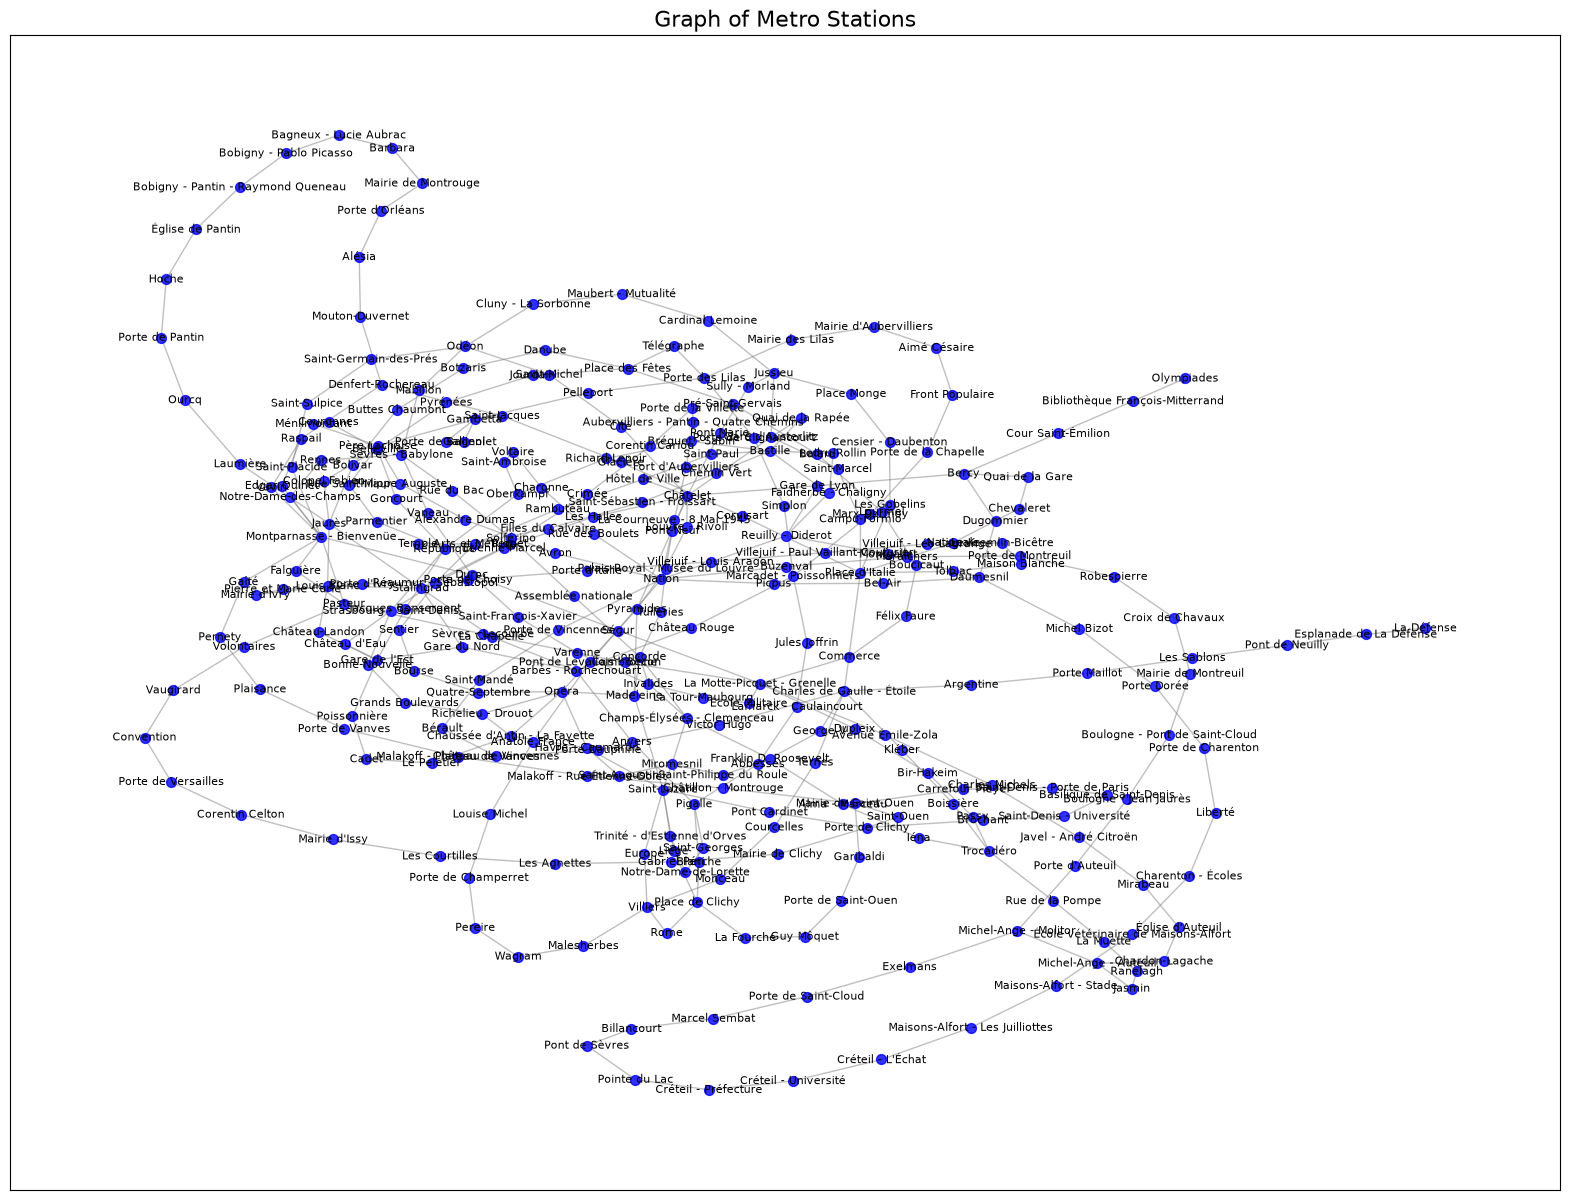

Removed edge: ('Mairie de Saint-Ouen', 'Garibaldi')
Removed edge: ('Bréguet - Sabin', 'Bastille')
Removed edge: ("Gare d'Austerlitz", 'Saint-Marcel')
Removed edge: ('Basilique de Saint-Denis', 'Saint-Denis - Porte de Paris')
Edge ('Saint-Marcel', "Gare d'Austerlitz") is not contournable and cannot be removed.
Removed edge: ('Miromesnil', 'Saint-Philippe du Roule')
Removed edge: ('Réaumur - Sébastopol', 'Sentier')
Removed edge: ('Arts et Métiers', 'Réaumur - Sébastopol')
Edge ('Guy Môquet', 'Porte de Saint-Ouen') is not contournable and cannot be removed.
Removed edge: ('Gambetta', 'Porte de Bagnolet')
Edges after removal: 369


In [17]:
# Function to remove edges based on the station_to_deleted DataFrame
def remove_edges_from_graph(G, station_to_deleted):
    """
    Remove edges from the graph based on a list of edges while ensuring they are contournable.

    Args:
        G (nx.Graph): The input graph.
        station_to_deleted (pd.DataFrame): DataFrame containing the 'de' and 'vers' columns.

    Returns:
        nx.Graph: The modified graph with edges removed.
    """
    for idx, row in station_to_deleted.iterrows():
        edge_to_remove = (row['de'], row['vers'])
        
        # Verify if the edge is contournable
        contournable_connections = find_contournable_connections(G)
        if edge_to_remove in contournable_connections or (edge_to_remove[::-1] in contournable_connections):
            try:
                # Remove the edge from the graph
                G.remove_edge(*edge_to_remove)
                print(f"Removed edge: {edge_to_remove}")
            except nx.NetworkXError as e:
                print(f"Failed to remove edge {edge_to_remove}: {e}")
        else:
            print(f"Edge {edge_to_remove} is not contournable and cannot be removed.")

    return G

# Plan complet du metro + liste des inter-stations supprimees (cas reel)
station_to_deleted = pd.read_csv(f'{DATA_DIR}/interstations_supprimees.csv', encoding='utf-8')

# Build the graph a partir du plan COMPLET, puis on retire les aretes supprimees
G_degraded_real = build_metro_graph(plan, station_positions, USE_POSITIONS, USE_FIXED_DISTANCE)

# Remove edges based on station_to_deleted while verifying contournable connections
G_degraded_real = remove_edges_from_graph(G_degraded_real, station_to_deleted)
print("Edges after removal:", G_degraded_real.number_of_edges())


## Visualisation des flux via la heatmap

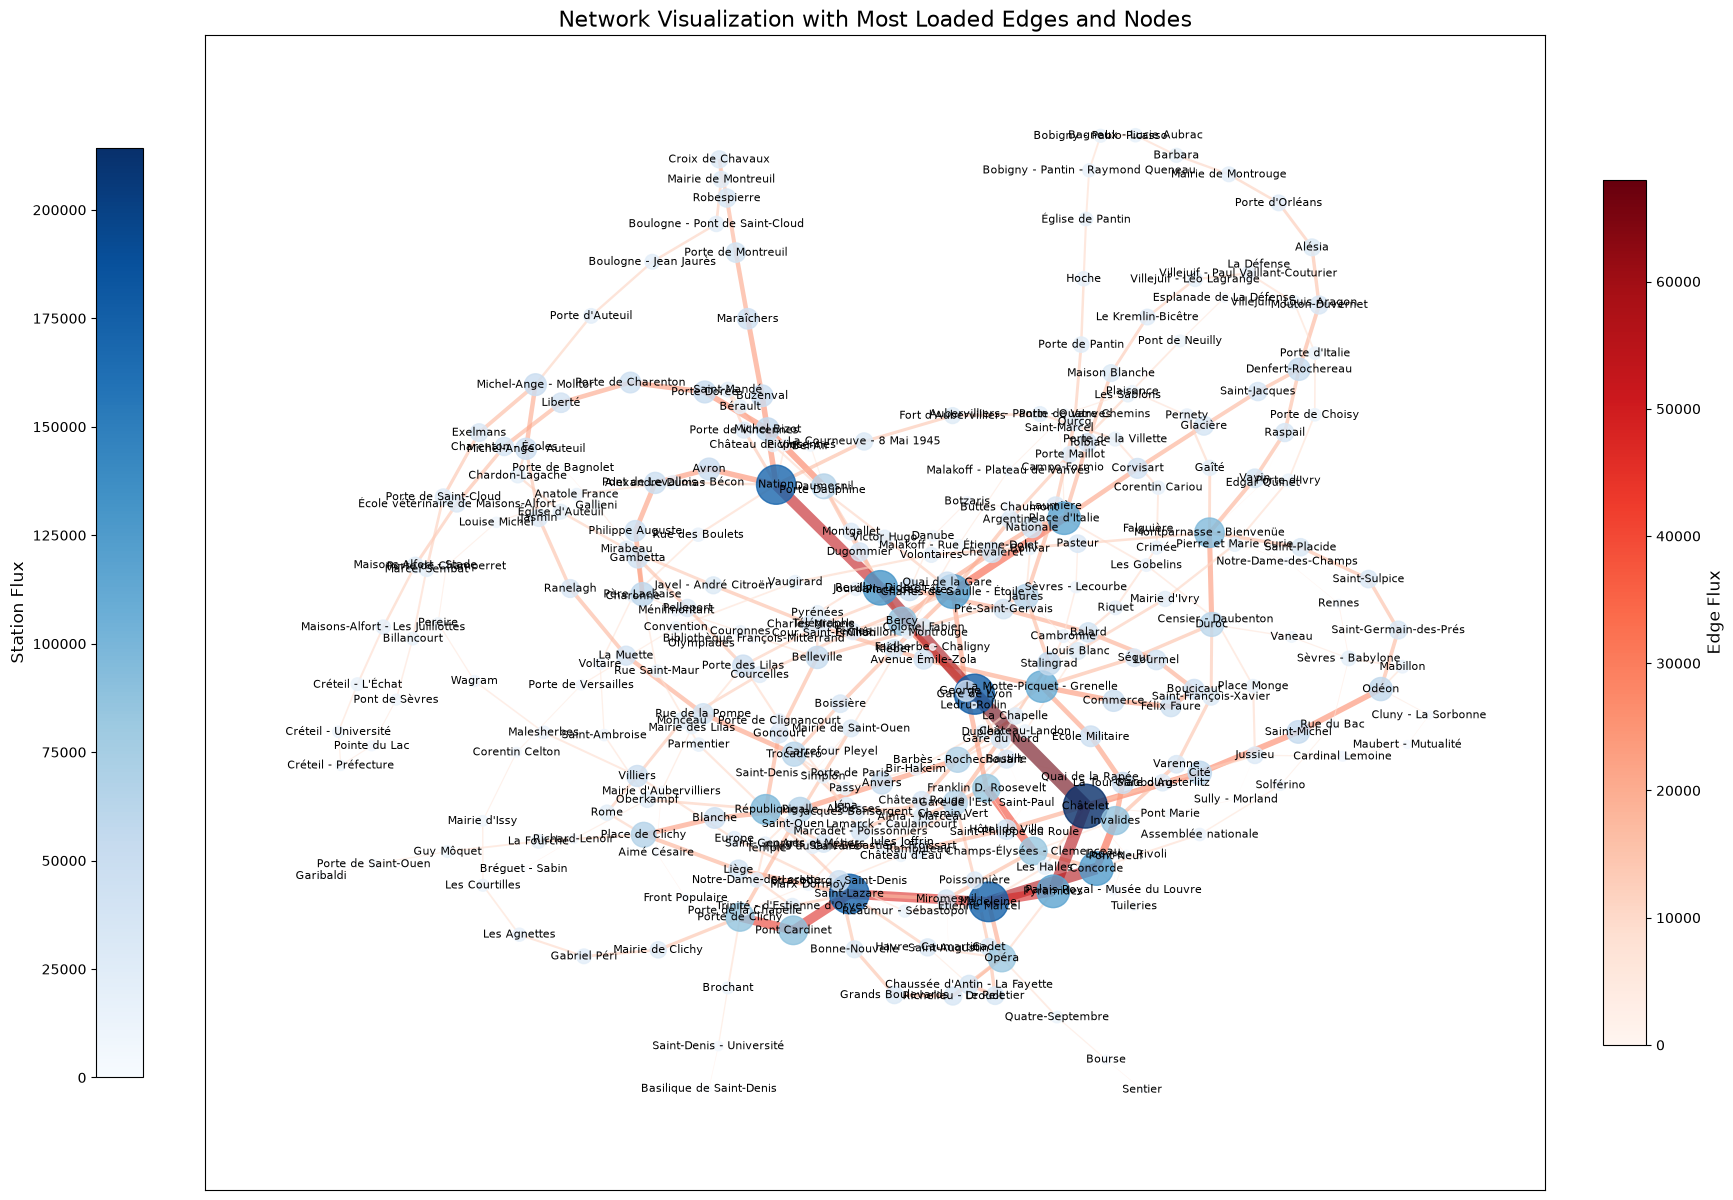

In [18]:
# Call the updated function
flux_par_arete, flux_par_station, travel_par_passager, total_passengers = calculate_passenger_flow(
    G_degraded_real, passagers, USE_PASSENGER_PONDERATION
)

# Call the function to visualize the network
visualize_network(
    G_degraded_real, flux_par_arete, flux_par_station, USE_POSITIONS, figsize=(20, 15)
)


In [19]:

# Call the function to display top flows
display_top_flows(flux_par_arete, flux_par_station, top_n=10)

Top 10 most loaded inter-station connections:
1. Châtelet -> Gare de Lyon: 67974.00 passengers
2. Gare de Lyon -> Reuilly - Diderot: 58919.00 passengers
3. Concorde -> Madeleine: 56447.00 passengers
4. Châtelet -> Pyramides: 56352.00 passengers
5. Nation -> Reuilly - Diderot: 53305.00 passengers
6. Madeleine -> Pyramides: 48560.00 passengers
7. Madeleine -> Saint-Lazare: 47236.00 passengers
8. Pont Cardinet -> Saint-Lazare: 46663.00 passengers
9. Pont Cardinet -> Porte de Clichy: 44151.00 passengers
10. Champs-Élysées - Clemenceau -> Franklin D. Roosevelt: 40590.00 passengers

Top 10 most loaded stations:
1. Châtelet: 214371.00 passengers
2. Gare de Lyon: 178225.00 passengers
3. Madeleine: 173636.00 passengers
4. Saint-Lazare: 172839.00 passengers
5. Nation: 170362.00 passengers
6. Reuilly - Diderot: 131785.00 passengers
7. Charles de Gaulle - Étoile: 126671.00 passengers
8. Concorde: 125253.00 passengers
9. Pyramides: 117861.00 passengers
10. Place d'Italie: 116898.00 passengers
